# Trajectories and Spatial Gene Modules

`01_core_workflow.ipynb` ended with nine Leiden clusters. Leiden always returns discrete bins, even when the underlying biology is a continuum. This notebook examines whether the clusters represent genuinely distinct populations or cuts through a gradient: PAGA tests cluster connectivity in expression space; diffusion pseudotime (DPT) orders cells along any continuum PAGA reveals.

The second half addresses a separate question: genes that co-vary spatially (rising and falling together across the tissue) indicate shared regulatory programs or shared cell-type residency. `tl.spatial_gene_modules` finds these groups directly from the spatial graph, without cluster labels or pseudotime.

Dataset: `ab.datasets.xenium()`, re-processed here so this notebook runs standalone.

In [ ]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import astrolabe as ab

## 1. Setup

Cluster identities from `01_core_workflow.ipynb` are the input to both trajectory analysis and gene-module discovery below, so this notebook reproduces that setup (load, filter, normalize, cluster) standalone rather than depending on the earlier notebook having run. One detail carried over deliberately: `tl.cluster` and `tl.umap` default to `neighbors_key='spatial_neighbors'`. For expression-based clusters, `neighbors_key='neighbors'` must be passed explicitly.

In [ ]:
mdata = ab.datasets.xenium()
ab.pipeline.filter_xenium(mdata)

ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata, n_top_genes=2000)

ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)  # transcriptomic graph -> uns['neighbors']
ab.tl.cluster(mdata, resolution=0.5, neighbors_key='neighbors')

mdata['xenium'].obs['leiden'].value_counts()

## 2. Testing cluster discreteness with PAGA

`tl.paga` abstracts the transcriptomic neighbor graph into a cluster-level connectivity graph: for every pair of Leiden clusters, normalized inter-cluster edge density is computed. Strong connectivity between two clusters indicates a continuum; weak connectivity everywhere indicates genuinely distinct populations.

`neighbors_key='neighbors'` is passed because PAGA must abstract the *expression* graph, not the spatial one.

In [3]:
ab.tl.paga(mdata, groupby='leiden', neighbors_key='neighbors')
ab.pl.paga_plot(mdata, threshold=0.05).show()

... storing 'feature_type' as categorical


... storing 'genome' as categorical


INFO:astrolabe.tl._trajectory:paga: 9 groups, results in uns['paga']


The PAGA graph at threshold=0.05 reveals which clusters share intermediate cell states. Epithelial clusters (0, 1, 5) are expected to be strongly connected to each other — they share canonical markers and likely represent a transcriptional continuum within the tumor epithelial lineage. Immune clusters (2=T-cell, 4=macrophage) are expected to be weakly connected to epithelial clusters (reflecting cross-compartment identity boundaries) but may connect to each other and to the fibroblast/pericyte cluster (3). Clusters 7 and 8 (ciliated, mast cells) are the most transcriptionally distinct and should appear as peripheral nodes with few thick edges — they are committed specialized states rather than transition intermediates.

Thick edges indicate clusters with high normalized connectivity — a hallmark of a continuum rather than two discrete populations. Clusters connected only by thin edges (below `threshold=0.05`) appear as expression-space islands with no intermediate cell states.

A hub-and-spoke topology is common in complex tissues: a broadly plastic state connected to several committed populations. Truly disconnected clusters indicate sharp fate boundaries rather than gradients. If all clusters are disconnected at this threshold, diffusion pseudotime has no meaningful axis to project onto.

## 3. Ordering cells along the trajectory

Diffusion pseudotime requires a root cell: DPT measures distance *from* that cell, so "early" and "late" are undefined without one. The root here is cluster 0 (the largest cluster in this data), set via `root_obs_key='leiden'`/`root_obs_val='0'`; the first cell in that group is used automatically. `tl.dpt` runs `sc.tl.diffmap` internally if it hasn't been computed.

In [4]:
ab.tl.dpt(mdata, root_obs_key='leiden', root_obs_val='0', neighbors_key='neighbors')

mdata['xenium'].obs['dpt_pseudotime'].describe()

INFO:astrolabe.tl._trajectory:dpt: root cell set to index 4 (first cell where obs['leiden'] == '0')


INFO:astrolabe.tl._trajectory:dpt: computing diffusion map (n_dcs=10)


INFO:astrolabe.tl._trajectory:dpt: pseudotime written to obs['dpt_pseudotime']


count    154270.000000
mean          0.339530
std           0.323911
min           0.000000
25%           0.056823
50%           0.094978
75%           0.708472
max           1.000000
Name: dpt_pseudotime, dtype: float64

The pseudotime distribution is strongly right-skewed: median = 0.095 but mean = 0.340. Half the cells (75,000+) have pseudotime below 0.095 — they are all near the root cluster 0 (tumor epithelium), which forms the dense early end of the trajectory. The long upper tail (75th percentile = 0.708, max = 1.0) represents cells in distant transcriptional states, likely immune (cluster 2) and rare populations (7, 8) at the far end of any continuum from the epithelial anchor. If pseudotime aligns with the tissue's spatial axis — tumor core → stromal margin → immune zone — the overlay below should show a smooth color gradient rather than sharp discontinuities at cluster boundaries.

Pseudotime is stored in `obs['dpt_pseudotime']` and can be passed directly to `pl.points(color=...)`. Comparing it against discrete Leiden labels on the tissue tests the continuum hypothesis: pseudotime that varies smoothly across cluster boundaries rather than jumping at the same lines Leiden drew is evidence that the gradient captures biology the hard labels discard.

The first `pl.points()` call below returns a lazy `SpatialPanel` — nothing renders until `.show()` is called.

In [5]:
# Not rendered yet -- pseudotime_panel is just a lazy SpatialPanel until .show()/repr triggers a draw.
pseudotime_panel = ab.pl.points(mdata, color='dpt_pseudotime')
type(pseudotime_panel)

astrolabe.pl._spatial.SpatialPanel

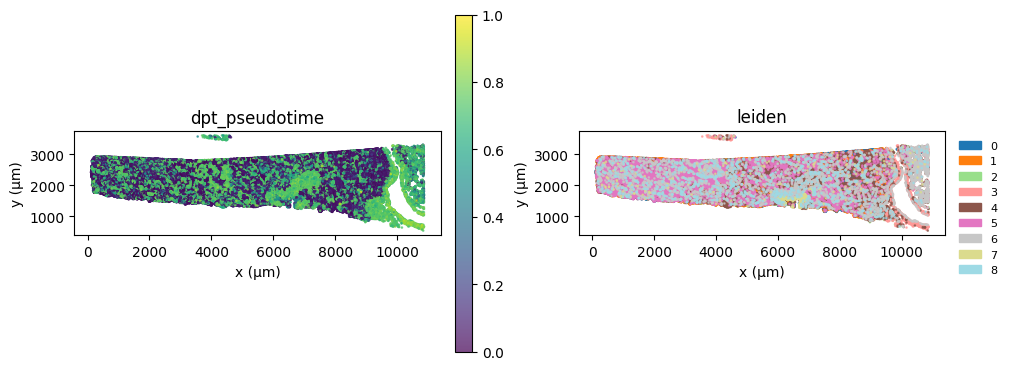

In [6]:
(pseudotime_panel | ab.pl.points(mdata, color='leiden')).show()

Comparing pseudotime to Leiden shows how well the two representations agree spatially. Where pseudotime varies smoothly *across* a Leiden cluster boundary (the color gradient doesn't jump at the same line as the cluster label), the discrete cluster label is cutting through a continuum rather than capturing a sharp biological transition. Where pseudotime and Leiden boundaries align closely (same spatial edge), the discrete label genuinely captures a cell-state boundary. In this lung cancer tissue, the tumor epithelial clusters (0, 1, 5) are expected to show smooth intra-cluster pseudotime variation while immune clusters (2, 4, 8) should appear as dense, uniform high-pseudotime zones far from the epithelial root.

## 4. Co-varying spatial gene programs

Trajectories describe continuity in *cell* identity. A separate question applies to *genes*: whether any are spatially co-expressed, rising and falling together across tissue, independently of cluster or pseudotime assignment. `tl.spatial_gene_modules` finds such groups from the spatial graph alone, without trajectory or cluster labels.

The function reads `obsp['{neighbors_key}_connectivities']` from a spatial graph, not the transcriptomic graph used for PAGA/DPT. `pipeline.filter_xenium` already built one during filtering (under `obsp['spatial_neighbors_connectivities']`), which matches the default `neighbors_key='spatial_neighbors'`.

In [7]:
modules = ab.tl.spatial_gene_modules(mdata, n_modules=8)
modules.groupby('module').size()

INFO:astrolabe.tl._gene_modules:spatial_gene_modules: building spatial_lag correlation matrix (377 × 377)


INFO:astrolabe.tl._gene_modules:spatial_gene_modules: clustering (hierarchical, k=8)


INFO:astrolabe.tl._gene_modules:spatial_gene_modules: scores stored in obsm['spatial_module_scores']


INFO:astrolabe.tl._gene_modules:spatial_gene_modules: 377 genes → 8 modules


module
0     32
1     35
2     36
3     31
4     58
5     21
6     15
7    149
dtype: int64

Module 7 is the largest at 149 genes (40% of the entire 377-gene panel). This over-representation is expected for a targeted panel: many genes in the panel are co-expressed because they were selected to co-vary with specific cell types, so one dominant co-expression community absorbs the majority of "constitutively expressed" housekeeping-like genes. Modules 0–3 (31–36 genes each) and module 4 (58 genes) represent tighter, more specialized programs — likely cell-type-specific markers rather than broadly expressed genes. Module 6 (15 genes) is the most specific, suggesting a niche program expressed in only a subset of cell types. The `largest_module` variable below identifies which module contributes most to the spatial score map.

Each module's per-cell score is in `obsm['spatial_module_scores']` — a `(n_cells, n_modules)` array, one column per module, computed as the mean expression of that module's genes. A spatially coherent pattern in the highest-scoring cells (rather than diffuse noise) confirms the module reflects genuine co-expressed structure.

largest module: 7, genes: ['ABCC11', 'ACTG2', 'ADAM28', 'ADH4', 'ADIPOQ', 'AHSP', 'ALAS2', 'ALDH1A3', 'ANGPT2', 'APOA5', 'APOBEC3A', 'AQP2', 'AQP8', 'ASCL1', 'ASCL3', 'BAMBI', 'BANK1', 'BBOX1', 'BMX', 'C15orf48', 'C5orf46', 'CCL27', 'CD19', 'CD1A', 'CD1C', 'CD1E', 'CD274', 'CD300E', 'CD5L', 'CD70', 'CD79A', 'CD83', 'CDH16', 'CHGA', 'CLCA1', 'CLEC10A', 'CLEC4E', 'CLECL1', 'COCH', 'CPA3', 'CRHBP', 'CSF3', 'CTSG', 'CXCL10', 'CXCL2', 'CYP1A1', 'CYP3A4', 'DERL3', 'DIRAS3', 'DMBT1', 'DPEP1', 'ESR1', 'FAS', 'FCER1A', 'FCN1', 'FCN2', 'FGFBP1', 'FGFBP2', 'FKBP11', 'FOXI1', 'FSTL3', 'FXYD2', 'GATA2', 'GCG', 'GEM', 'GHRL', 'GKN2', 'GLYATL1', 'GNLY', 'GYPA', 'GYPB', 'GZMB', 'HAMP', 'HEMGN', 'HEPACAM2', 'HES4', 'HLA-DQB2', 'HMGCS2', 'HPX', 'IL1R2', 'IL1RL1', 'IL3RA', 'INS', 'KIT', 'KLRC1', 'KLRD1', 'KNG1', 'KRT20', 'LAG3', 'LGI4', 'LGR5', 'LIF', 'LILRA4', 'LILRA5', 'LY6D', 'LYVE1', 'MFAP5', 'MLANA', 'MS4A1', 'MS4A2', 'MYBPC1', 'MZB1', 'NAT8', 'OPRPN', 'PCP4', 'PDCD1', 'PGR', 'PLAC9', 'PLCG2', 'PLD4

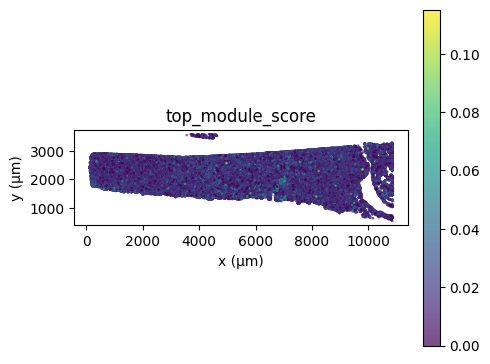

In [8]:
largest_module = modules.groupby('module').size().idxmax()
print(f"largest module: {largest_module}, genes: {modules.loc[modules['module'] == largest_module, 'gene'].tolist()}")

mdata['xenium'].obs['top_module_score'] = mdata['xenium'].obsm['spatial_module_scores'][:, largest_module]
ab.pl.points(mdata, color='top_module_score').show()

The largest spatial module's score should map onto recognizable tissue compartments. A spatially coherent pattern (where high-scoring cells form contiguous regions matching known anatomical structures) validates that spatial co-expression captures genuine tissue organization rather than noise. Module 7 (149 genes, the largest) likely contains broadly expressed genes shared across many cell types; its spatial score would be elevated everywhere, making it less useful as a cell-type discriminator than the smaller, more specific modules. For downstream use, the smaller modules (5–6: 15–21 genes) are the best candidates for single-module marker sets.

## 5. Self-organizing maps

Self-organizing maps (SOMs) are a topology-preserving dimensionality reduction technique that maps high-dimensional data onto a fixed 2-D grid of nodes. Unlike UMAP or PCA, which produce a continuous embedding, the SOM grid is discrete and reproducible, making it useful for three distinct analyses:

1. **Cell clustering** — each cell is assigned to its best-matching node (BMU). Nearby nodes hold similar cells; the U-matrix (unified distance matrix) reveals natural cluster boundaries without external labels.
2. **Gene module discovery** — train on the transposed matrix (genes as observations, cells as features) to group co-regulated genes without requiring a spatial graph.
3. **Subcellular spatial domains** — train on normalized intracellular transcript positions to find recurring spatial patterns *within* cells (nuclear accumulation, peripheral ring, polar asymmetry, etc.).

Requires the `minisom` optional dependency (`uv add 'astrolabe[som]'`).

### 5a. Cell-level SOM clustering

`tl.som` auto-sizes the grid using the heuristic `ceil(sqrt(5 × sqrt(n_cells)))`: for 154,270 cells this gives a 45×45 grid (2,025 nodes) and defaults to 100 × n_cells = 15.4 million training iterations, both impractical for a tutorial run. The example below uses `x=20, y=20` (400 nodes, enough to resolve the 9 Leiden clusters and their sub-states) and caps `n_iter=100_000` (about 0.65 random passes through the data, sufficient for a converged cluster topology on pre-reduced PCA). Setting `n_modules=16` in `tl.som_gene_modules` provides finer gene grouping than the 8 used for spatial modules because gene-level SOM operates on 377 observations (genes) rather than 154k cells.

In [9]:
# Train a SOM on the PCA embedding.
# x=20, y=20: 400 nodes (enough to resolve 9+ clusters and sub-states).
# n_iter=100_000: caps training at a manageable wall time; auto-default of
# 100*n_cells = 15.4M iterations would take hours on 154k cells.
ab.tl.som(mdata, use_rep='X_pca', x=20, y=20, n_iter=100_000, seed=42)

xen = mdata['xenium']
print(f"Grid: {xen.uns['som']['params']['x']}x{xen.uns['som']['params']['y']}")
xen.obs['som_cluster'].value_counts().sort_index()

INFO:astrolabe.tl._som:som: training 20×20 grid on 154270 cells (50 features, 100000 iterations)


INFO:astrolabe.tl._som:som: done → obsm['X_som'], obs['som_cluster'], uns['som']


Grid: 20x20


som_cluster
0_0     317
0_1     171
0_10    683
0_11    331
0_12    253
       ... 
9_5     151
9_6     188
9_7     343
9_8     285
9_9     315
Name: count, Length: 400, dtype: int64

The 20×20 grid assigns 154,270 cells to 400 nodes — a mean of ~386 cells per node, ranging from ~151 to ~683. Node population spread indicates transcriptional density: densely populated nodes hold common cell states (likely the large tumor epithelial clusters 0 and 1), while sparsely populated nodes correspond to rare or transitional states. With 400 nodes against 9 Leiden clusters, the SOM resolves sub-cluster heterogeneity that Leiden's single-resolution partition misses — adjacent nodes that Leiden lumped into one cluster may represent sub-populations with distinct marker profiles. The U-matrix and hit-map below show where these boundaries and density peaks lie.

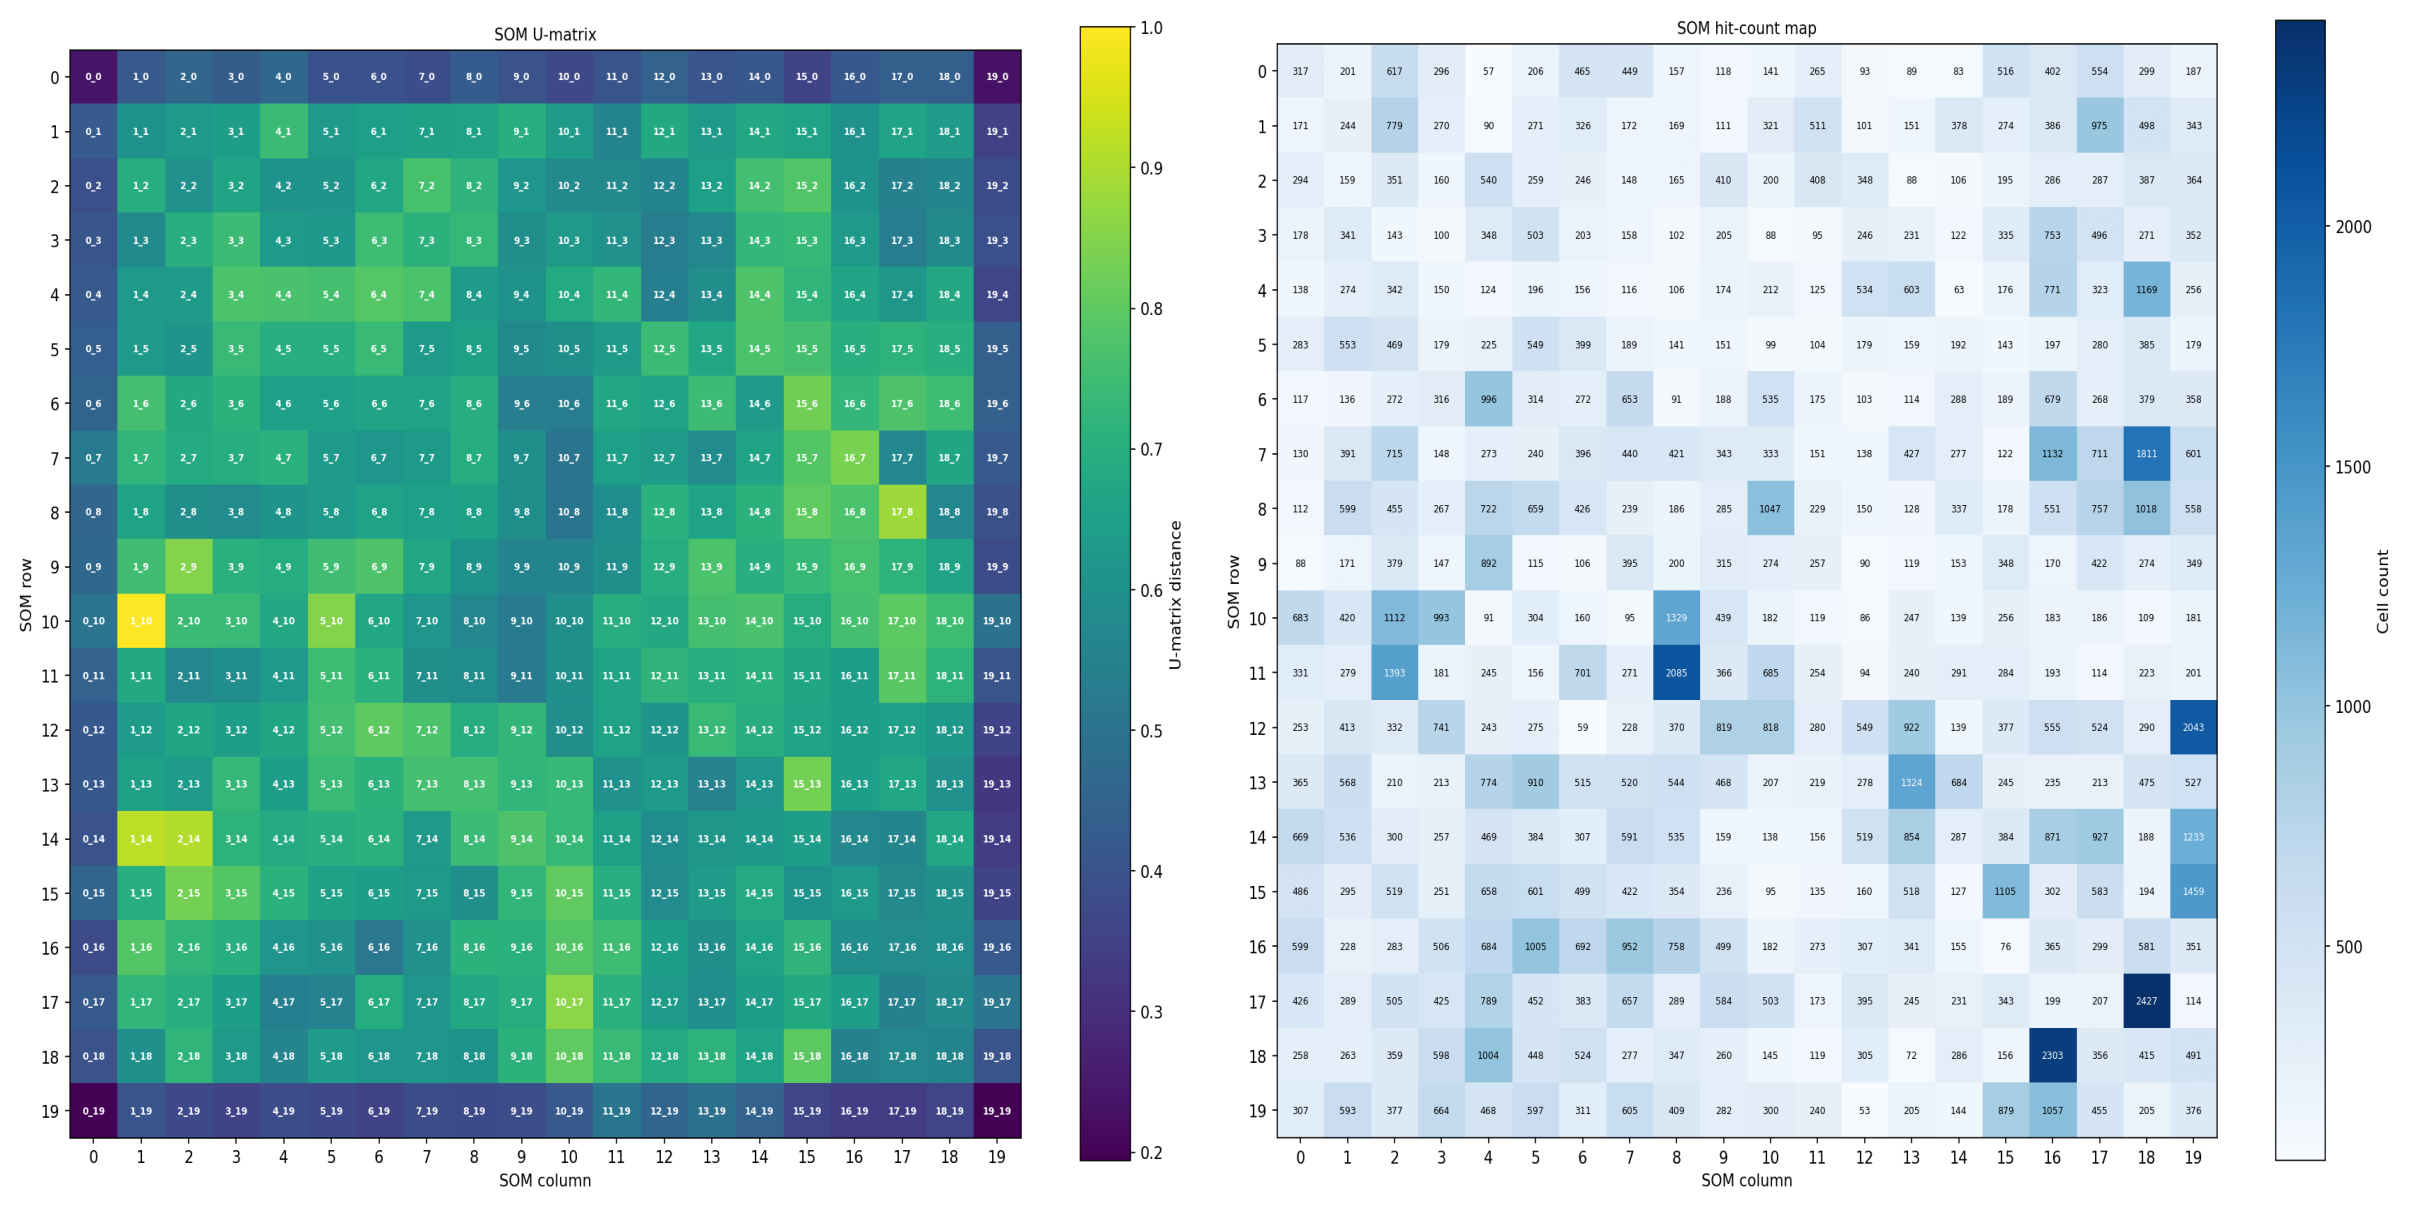

In [10]:
# U-matrix reveals cluster boundaries (high = boundary between distinct cell states)
# Hit map shows how many cells land on each node (dense = common state)
(ab.pl.som_umatrix(mdata) | ab.pl.som_hits(mdata)).show()

The U-matrix encodes the mean distance from each node to its immediate grid neighbors: bright ridges mark transcriptional boundaries between distinct cell states; dark valleys mark plateaus of similar cells. A hit map that is unevenly concentrated (a few very dense nodes surrounded by sparse ones) confirms the dataset is dominated by a small number of abundant cell types. Comparing the U-matrix ridge pattern against the spatial tissue view (next cell) reveals whether transcriptional boundaries correspond to spatial tissue compartment edges: aligned boundaries indicate anatomy-driven cell identity, while scattered boundaries suggest continuous transcriptional variation independent of tissue structure.

C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\pl\_spatial.py:324: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


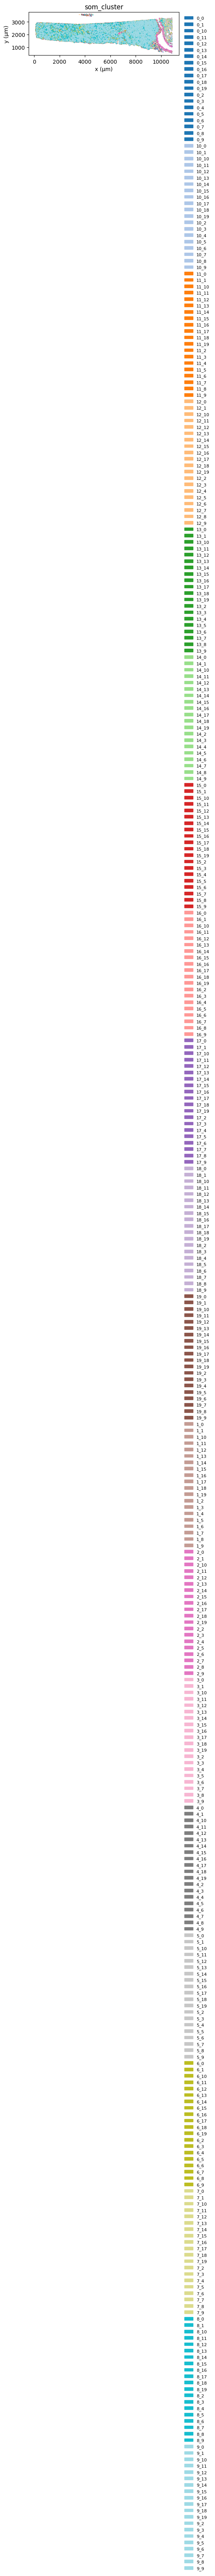

In [11]:
# SOM clusters in tissue space — compare with expression-based Leiden clusters
ab.pl.points(mdata, color='som_cluster').show()

The SOM tissue map uses 400 distinct colors (one per grid node), so cells assigned to nearby nodes in expression space appear in similar hues — a smooth color gradient in the tissue plot indicates a transcriptional continuum, while sharp color jumps at anatomical boundaries (tumor nest edges, stromal–immune interfaces) confirm those are real cell-state transitions. Comparing this to the 9-color Leiden map: regions that are uniform in Leiden but show SOM color variation contain the intra-cluster heterogeneity the discrete partition suppressed. If the SOM and Leiden boundaries coincide everywhere, the resolution chosen for SOM (400 nodes) is not revealing additional sub-structure beyond what Leiden captured.

### 5b. Gene modules via SOM

`tl.som_gene_modules` trains on the gene-by-cell matrix (each gene as an observation, cells as features) to cluster genes into co-expression modules. Unlike `tl.spatial_gene_modules` it requires no spatial graph — it captures purely transcriptomic co-regulation.


In [12]:
som_genes = ab.tl.som_gene_modules(mdata, n_modules=16, seed=42)
print(som_genes.groupby('module').size().sort_values(ascending=False))

# Inspect the most-populated module
largest_mod = som_genes.groupby('module').size().idxmax()
print(f'Largest module ({largest_mod}):', som_genes.loc[som_genes['module'] == largest_mod, 'gene'].tolist()[:10])

INFO:astrolabe.tl._som:som_gene_modules: training 4×4 grid on 377 genes (154270 cells, 37700 iterations)


INFO:astrolabe.tl._som:som_gene_modules: 377 genes → 16 modules in var['som_gene_module']


module
2_0    231
1_0     21
2_1     21
3_0     13
1_1     12
0_0     12
2_2     10
0_3      9
0_1      8
0_2      8
3_2      7
2_3      6
3_3      6
3_1      5
1_3      4
1_2      4
dtype: int64
Largest module (2_0): ['ABCC11', 'ACKR1', 'ADGRE1', 'ADH1C', 'ADH4', 'ADIPOQ', 'AGER', 'AHSP', 'ALAS2', 'ALDH1A3']


Module `2_0` absorbs 231 of 377 genes (61%): a dominance pattern expected for a targeted Xenium panel where many genes were selected precisely because they co-vary with the same abundant cell types (epithelial markers all rise together in tumor nests). The two 21-gene modules (`1_0`, `2_1`) and the 13-gene module (`3_0`) are the most gene-specific; these smaller modules are likely better single-module discriminators for immune or stromal sub-populations than the giant bulk module. The first genes listed in module `2_0` (ABCC11, ACKR1, ADGRE1, ADH1C, ADIPOQ, AGER, AHSP, ALAS2, ALDH1A3, spanning macrophage receptors, hemoglobin biosynthesis, and adipokines) reflect diverse biology co-loaded into a catch-all module rather than a coherent program; the smaller modules deserve inspection for cell-type-specific regulons.

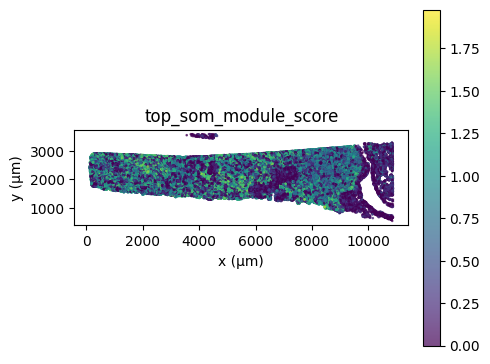

In [13]:
# Score each cell for each gene module and show the top-scoring module spatially
scores = xen.obsm['som_gene_modules_scores']
top_mod_idx = scores.mean(axis=0).argmax()
xen.obs['top_som_module_score'] = scores[:, top_mod_idx]
ab.pl.points(mdata, color='top_som_module_score').show()

The top-scoring SOM gene module's spatial pattern tests whether the module captures a coherent tissue program. Because module `2_0` contains 61% of genes including many broadly expressed markers, its score is expected to be high everywhere — producing a noisy, undifferentiated spatial map rather than distinct compartments. For practical use, inspect the smaller modules (5–13 genes) where high module scores should be restricted to specific anatomical zones: a stromal module scoring high in LTBP2/PDGFRB-rich fibroblast belts, or an immune module peaking in the lymphocyte-dense zones around tumor margins.

### 5c. Subcellular spatial domains

SOM can also be applied at the sub-cellular level. Each transcript's position is normalized relative to its cell's centroid and equivalent radius, making cells of different sizes comparable. The SOM then discovers recurring *spatial patterns* across all cells: a node at the grid center may correspond to nuclear accumulation, while peripheral nodes may represent membrane-enriched transcripts.

Results are stored as:
- `obs['som_subcellular_dominant']` — the dominant domain per cell (useful for tissue-level spatial maps)
- `obsm['som_subcellular_fractions']` — full `(n_cells, n_domains)` domain composition matrix


In [14]:
# Load the full transcript table into mdata['xenium'].uns['transcripts']
# read_xenium_transcripts returns None when inplace=True (default); transcripts
# are stored in uns, not returned.
ab.io.read_xenium_transcripts(mdata)
transcripts = mdata['xenium'].uns['transcripts']

# 5x5 grid = 25 subcellular domains; train on normalized intracellular (dx/r, dy/r) positions
tx_domains = ab.tl.som_subcellular_domains(mdata, transcripts, x=5, y=5, seed=42)
print(f'Assigned {len(tx_domains)} transcripts to {tx_domains["domain"].nunique()} domains')
xen.obs['som_subcellular_dominant'].value_counts().head(8)

INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\notebooks\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 10606835 transcript detections


INFO:astrolabe.tl._som:som_subcellular_domains: training 5×5 grid on 9131749 transcripts (154270 cells, 1000000 iter)


INFO:astrolabe.tl._som:som_subcellular_domains: 25 domains → obs['som_subcellular_dominant'], obsm['som_subcellular_fractions']


Assigned 9131749 transcripts to 25 domains


som_subcellular_dominant
0_4    13958
1_2    10915
3_1    10159
4_1    10157
0_2     8956
0_3     8903
1_1     8637
0_1     7081
Name: count, dtype: int64

9,131,749 of 10,606,835 transcripts (86%) passed quality filters and were assigned to the 5×5 = 25 subcellular domains. The dominant domain for each cell is a corner or edge node (`0_4`, `1_2`, `3_1`, `4_1`) rather than the center, reflecting that most transcripts in FFPE Xenium data localize to the cell periphery and cytoplasm rather than the nucleus center. The 5×5 grid (25 domains) is intentionally small: with only 2 input dimensions (normalized x and y), a finer grid would over-partition the smooth intracellular position distribution. Domain `0_4` dominates 13,958 cells (9%), likely the top-right corner of the intracellular coordinate frame, corresponding to one of the four peripheral quadrants.

In [15]:
# Draw transcript positions inside cell outlines, coloured by domain label
# Reveals whether domains correspond to nuclear / cytoplasmic / peripheral regions
ab.pl.som_subcellular_plot(mdata, tx_domains, max_cells=150).show()

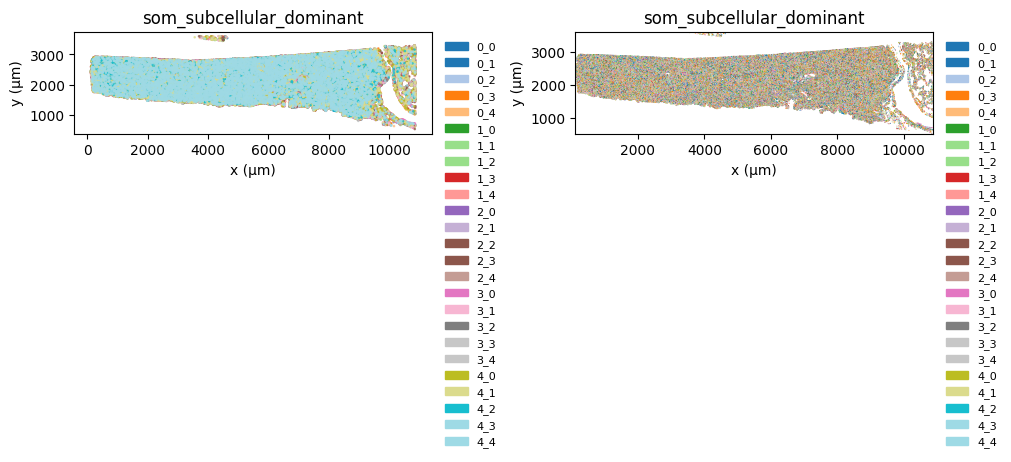

In [16]:
# Tissue-level view: which subcellular pattern dominates each cell?
# Cells of the same type or in the same neighbourhood may share a dominant domain
(ab.pl.points(mdata, color='som_subcellular_dominant')
 | ab.pl.boundaries(mdata, color='som_subcellular_dominant')).show()

The tissue-level view of dominant subcellular domain reveals whether intracellular transcript organization is spatially structured or cell-autonomous. If cells in the same tissue compartment share a dominant domain (e.g., all tumor cells in a nest pointing their dominant transcript accumulation in the same direction), it suggests a collective polarity signal — perhaps aligned with a gradient or a shared vasculature axis. Random domain assignment across neighbors indicates transcript localization is cell-intrinsic rather than tissue-level coordinated. The boundary overlay separates the cell polygon from its domain assignment, making it easier to see if large epithelial cells vs. small immune cells differ in their dominant intracellular pattern.

## Summary

Two findings, both pointing beyond the discrete-cluster summary from `01_core_workflow.ipynb`: the PAGA/DPT trajectory shows cluster identity is at least partly a continuum; the spatial gene module identifies a co-expression structure independent of cluster labels. Either finding could seed a hypothesis about cell-type-driven contact effects explored in `03_neighborhood_analysis.ipynb`.